In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

In [7]:
# Load the raw training dataset
df = pd.read_csv("training_data_202601.csv")
df_clean = df.copy()
# Target and identifier columns
target_col = "Painting"
id_col = "unique_id"

# Numeric columns
numeric_cols = [
    "On a scale of 1–10, how intense is the emotion conveyed by the artwork?",
    "How many prominent colours do you notice in this painting?",
    "How many objects caught your eye in the painting?"
]

# Likert-style columns such as "1 - Strongly disagree", "5 - Strongly agree"
likert_cols = [
    "This art piece makes me feel sombre.",
    "This art piece makes me feel content.",
    "This art piece makes me feel calm.",
    "This art piece makes me feel uneasy."
]

# Money column with messy free-form responses
money_col = "How much (in Canadian dollars) would you be willing to pay for this painting?"

# multi-select categorical columns
multi_select_cols = [
    "If you could purchase this painting, which room would you put that painting in?",
    "If you could view this art in person, who would you want to view it with?",
    "What season does this art piece remind you of?"
]

# Free-text columns
text_cols = [
    "Describe how this painting makes you feel.",
    "If this painting was a food, what would be?",
    "Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting."
]
# Strip whitespace for string values
for col in df_clean.columns:
    if df_clean[col].dtype == "object":
        df_clean[col] = df_clean[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

# Clean the Likert columns
# Extract the leading number from a Likert-style response
def extract_rating(x):
    if pd.isna(x):
        return np.nan

    match = re.match(r"^\s*(\d+)", str(x))
    if match:
        return float(match.group(1))
    return np.nan

# Apply to each Likert column
for col in likert_cols:
    df_clean[col] = df_clean[col].apply(extract_rating)

# Clean the free-text columns
# Basic text cleaning: lowercase, trim, collapse repeated spaces
def clean_text(x):
    if pd.isna(x):
        return ""

    s = str(x).lower().strip()
    s = re.sub(r"\s+", " ", s)
    return s

# Apply to each text column
for col in text_cols:
    df_clean[col] = df_clean[col].apply(clean_text)

    
# Clean the multi-select categorical columns
# Standardize multi-select categorical responses
def clean_multiselect(x):
    if pd.isna(x):
        return np.nan

    s = str(x).lower().strip()

    # Normalize separators
    s = s.replace(";", ",")
    s = s.replace("|", ",")
    s = s.replace("/", ",")

    # Split into items, trim spaces, remove empty items
    parts = [p.strip() for p in s.split(",") if p.strip()]

    # Sort so equivalent answers become identical
    parts = sorted(parts)

    if len(parts) == 0:
        return np.nan

    return ",".join(parts)

# Apply to each multi-select column
for col in multi_select_cols:
    df_clean[col] = df_clean[col].apply(clean_multiselect)
    
# Clean the money column
def parse_money(x):
    """
    Convert willingness-to-pay text into a numeric value.

    Rules:
    - Missing -> NaN
    - Remove common currency text/symbols
    - Range like '200-300' -> midpoint 250
    - Shorthand like '1k' -> 1000
    - True negatives like '-50' are kept for now, so we can clean them explicitly later
    """
    if pd.isna(x):
        return np.nan

    s = str(x).lower().strip()
    s = s.replace("$", "")
    s = s.replace(",", "")
    s = s.replace("cad", "")
    s = s.replace("dollars", "")
    s = s.replace("dollar", "")
    s = re.sub(r"\s+", " ", s)

    # Case 1: numeric range like 200-300 or 1k-2k
    range_match = re.search(r'(\d*\.?\d+)\s*(k?)\s*-\s*(\d*\.?\d+)\s*(k?)', s)
    if range_match:
        a = float(range_match.group(1))
        b = float(range_match.group(3))

        if range_match.group(2) == "k":
            a *= 1000
        if range_match.group(4) == "k":
            b *= 1000

        return (a + b) / 2

    # Case 2: single number, optionally negative, optionally with k
    single_match = re.search(r'(?<!\w)(-?\d*\.?\d+)\s*(k?)', s)
    if single_match:
        val = float(single_match.group(1))
        if single_match.group(2) == "k":
            val *= 1000
        return val

    return np.nan

money_col = "How much (in Canadian dollars) would you be willing to pay for this painting?"

df_clean[money_col] = df_clean[money_col].apply(parse_money)

# Save cleaned dataset for later modeling
df_clean.to_csv("clean_dataset.csv", index=False)

In [4]:
df = pd.read_csv("clean_dataset.csv")

target_col = "Painting"

X = df.drop(columns=[target_col])
y = df[target_col].values

labels = {v:i for i,v in enumerate(np.unique(y))}
y = np.array([labels[i] for i in y])

# Cross Validation
np.random.seed(42)

indices = np.arange(len(X))
np.random.shuffle(indices)

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

# split
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)


X_train = X_train.apply(pd.to_numeric, errors='coerce')
X_test = X_test.apply(pd.to_numeric, errors='coerce')

X_train.fillna(0, inplace=True)
X_test.fillna(0, inplace=True)

X_train = X_train.values.astype(float)
X_test = X_test.values.astype(float)


mean = X_train.mean(axis=0)
std = X_train.std(axis=0) + 1e-8

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std


Train size: (1348, 15)
Test size: (338, 15)


In [5]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def one_hot(y, num_classes):
    y_onehot = np.zeros((len(y), num_classes))
    y_onehot[np.arange(len(y)), y] = 1
    return y_onehot

def train_lr(X, y, lr=0.001, epochs=800, nabla=0.01):
    n_samples, n_features = X.shape
    num_classes = len(np.unique(y))

    W = np.zeros((n_features, num_classes))
    b = np.zeros((1, num_classes))

    y_onehot = one_hot(y, num_classes)

    for _ in range(epochs):
        logits = X @ W + b
        probs = softmax(logits)
        
        loss = -np.mean(np.sum(y_onehot * np.log(probs + 1e-9), axis=1))
        loss += nabla * np.sum(W * W) # L2 Regularization

        dZ = probs - y_onehot
        dW = (X.T @ dZ) / n_samples
        dW += 2 * nabla * W
        db = np.mean(dZ, axis=0, keepdims=True)

        W -= lr * dW
        b -= lr * db

    return W, b

def predict(X, W, b):
    logits = X @ W + b
    probs = softmax(logits)
    return np.argmax(probs, axis=1)

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


# K-Fold Cross Validation
def k_fold_cv_lr(X, y, lr, epochs, nabla, k=5):

    n = len(X)
    indices = np.arange(n)
    np.random.shuffle(indices)

    fold_size = n // k
    scores = []

    for i in range(k):
        start = i * fold_size
        end = start + fold_size

        val_idx = indices[start:end]
        train_idx = np.concatenate([indices[:start], indices[end:]])

        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]

        mean = X_tr.mean(axis=0)
        std = X_tr.std(axis=0) + 1e-8

        X_tr = (X_tr - mean) / std
        X_val = (X_val - mean) / std

        # Use lr in lr list
        W, b = train_lr(X_tr, y_tr, lr=lr, epochs=epochs, nabla=nabla)

        y_pred = predict(X_val, W, b)
        acc = accuracy(y_val, y_pred)

        scores.append(acc)

    return np.mean(scores)

lr_list = [0.01,0.005, 0.001]
epochs_list = [500, 800, 1000]
nabla_list = [0, 0.01, 0.001]

results = {}

for lr in lr_list:
    for epochs in epochs_list:
        for nabla in nabla_list:
            acc = k_fold_cv_lr(X_train, y_train, lr=lr, epochs=epochs, nabla=nabla, k=5)
            results[(lr, epochs, nabla)] = acc

best_params = max(results, key=results.get)

best_lr, best_epochs, best_nabla = best_params

print("\nBest params:", best_lr, best_epochs, best_nabla)
print("Best CV Accuracy:", results[best_params])

W, b = train_lr(X_train, y_train, lr=best_lr)

y_test_pred = predict(X_test, W, b)

print("\nFinal Test Accuracy:", accuracy(y_test, y_test_pred))


Best params: 0.01 1000 0
Best CV Accuracy: 0.7405204460966544

Final Test Accuracy: 0.6804733727810651


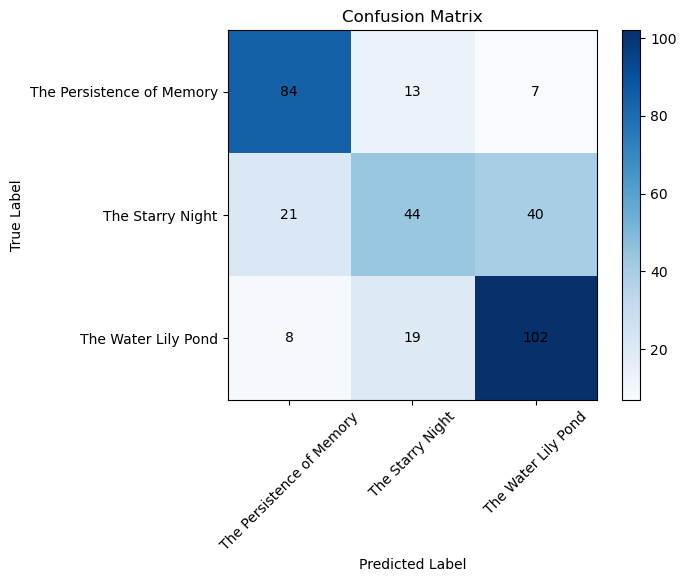

In [12]:
def confusion_matrix(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    
    for i in range(len(y_true)):
        cm[y_true[i], y_pred[i]] += 1
        
    return cm

num_classes = len(np.unique(y_train))

cm = confusion_matrix(y_test, y_test_pred, num_classes)

label_names = sorted(df[target_col].unique())

plt.figure()

plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(np.arange(num_classes), label_names, rotation=45)
plt.yticks(np.arange(num_classes), label_names)

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()